In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import scipy as sc
from scipy import sparse
import warnings
from scipy.optimize import fsolve
from __future__ import annotations
from numba import njit, prange, set_num_threads
from scipy.signal import fftconvolve
warnings.filterwarnings('ignore')

# Define + register custom colormap early so it's available to all later plots
m_cols = plt.cm.magma(np.linspace(0, 1, 256))
p_cols = plt.cm.plasma(np.linspace(0, 1, 256))
plagma_cmap = LinearSegmentedColormap.from_list('plagma', 0.60 * m_cols + 0.40 * p_cols)
if 'plagma' not in plt.colormaps():
    plt.colormaps.register(plagma_cmap)

print("✓ All imports successful!")
print("✓ Custom colormap 'plagma' is defined and registered")

✓ All imports successful!
✓ Custom colormap 'plagma' is defined and registered


In [2]:
# Spatial parameters
d = 2  # dimension
N = 128 + 1  # grid points per dimension CHANGE BACK TO 32 BEFORE YOU RUN
dx = 2.0 / (N - 1)  # spatial step
x_grid = np.linspace(-1.0, 1.0, N)  # spatial grid maybe this should be changed too

# Temporal parameters
dt = 0.1  # time step
T = 90 # final time
time_steps = int(np.floor(T / dt)) + 1  # number of time steps

# Interaction parameters
beta = 0.5  # weighting parameter
R = 0.2  # interaction radius

# Initial opinion state
w_init = np.array([0.5, 0.5])  # initial w in [0,1]^d

print(f"Spatial domain: {d}D with N={N} points (dx={dx:.4f})")
print(f"Time domain: T={T} with dt={dt} (time_steps={time_steps})")
print(f"Initial opinion: w(0) = {w_init}")

Spatial domain: 2D with N=129 points (dx=0.0156)
Time domain: T=90 with dt=0.1 (time_steps=901)
Initial opinion: w(0) = [0.5 0.5]


In [3]:
xgrid_try = np.linspace(-1+dx/2, 1-dx/2, N)
# Define initial density
def initial_density(x):
    """Initial density in spatial domain only"""
    return 1.0  # uniform

# Create and normalize initial condition: shape (N^d,)
init_cond = np.array([initial_density(np.array([x1, x2])) 
                      for x1 in x_grid for x2 in x_grid])
init_cond = init_cond.reshape(N**d)

# Normalize to unit mass
initial_mass = np.sum(init_cond) * (dx**2)
init_cond /= initial_mass

print(f"Initial condition shape: {init_cond.shape}")
print(f"Initial mass (normalized): {np.sum(init_cond) * (dx**2):.6f}")

Initial condition shape: (16641,)
Initial mass (normalized): 1.000000


In [4]:
def kahan_sum(values):
    s = 0.0
    c = 0.0
    for v in values:
        y = v - c
        t = s + y
        c = (t - s) - y
        s = t
    return s

def variance(f_n):
    dA = dx ** 2

    X, Y = np.meshgrid(xgrid_try, xgrid_try, indexing='ij')

    # Flatten everything so both components use identical summation order
    F = f_n.ravel()
    Xf = X.ravel()
    Yf = Y.ravel()
    
    Ex = kahan_sum(Xf * F) * dA
    Ey = kahan_sum(Yf * F) * dA

    # Second moment using |x|^2
    RX = Xf**2 * F
    RY = Yf**2 * F
    mX = kahan_sum(RX) * dA
    mY = kahan_sum(RY) * dA

    Var = mX + mY - (Ex**2 + Ey**2)

    return Var, [Ex, Ey]


In [5]:
@njit(inline="always", cache=True)
def _q(s):
    den = s * s + (1 - s) * (1 - s)
    return s * s / den


@njit(inline="always", cache=True)
def _phi(delta0, delta1, w0, beta, r1, r2, component):
    a0 = abs(delta0)
    a1 = abs(delta1)
    weighted = w0 * a0 + (1 - w0) * a1
    p = (
        beta * a0 + (1 - beta) * weighted
        if component == 0
        else beta * a1 + (1 - beta) * weighted
    )
    if p < r1:
        return 1.0
    if p >= r2:
        return 0.0
    return _q((r2 - p) / (r2 - r1))


@njit(inline="always", cache=True)
def _rad(length, dx, N):
    if not np.isfinite(length):
        return N
    return max(0, min(int(length / dx), N))

In [6]:
@njit(cache=True)
def _tight(N, dx, r2, beta, w0, r1):
    om = 1 - beta
    w1 = 1 - w0
    ds = (beta + om * w0, om * w1, om * w0, beta + om * w1)
    ls = np.empty(4)
    for z in range(4):
        ls[z] = np.inf if ds[z] <= 0 else r2 / ds[z]
    rs = np.empty(4, np.int64)
    for z in range(4):
        rs[z] = _rad(ls[z], dx, N)

    r11, r12, r21, r22 = rs
    s0 = np.empty((2 * r11 + 1, 2 * r12 + 1))
    s1 = np.empty((2 * r21 + 1, 2 * r22 + 1))
    for a in range(s0.shape[0]):
        for b in range(s0.shape[1]):
            s0[a, b] = _phi(
                (a - r11) * dx, (b - r12) * dx, w0, beta, r1, r2, 0
            )
    for a in range(s1.shape[0]):
        for b in range(s1.shape[1]):
            s1[a, b] = _phi(
                (a - r21) * dx, (b - r22) * dx, w0, beta, r1, r2, 1
            )
    return s0, s1, np.array([[r11, r12], [r21, r22]])


def tight_rectangle(N, r1, r2, beta, w0, dx=None):
    """Construct the same compact interaction rectangles as the direct solver."""
    if dx is None:
        dx = 2 / (N - 1)
    if not (0 <= w0 <= 1):
        raise ValueError("w0 must lie in [0, 1].")
    if not (0 <= r1 < r2):
        raise ValueError("Require 0 <= r1 < r2.")
    a, b, rho = _tight(N, dx, r2, beta, w0, r1)
    return [a, b], rho


In [7]:
@njit(cache=True)
def _transport_kernels(shape, rho0, rho1, dx, w0, beta, r1, r2, direction):
    """Build phi*displacement and its constrained w0 derivative."""
    h = np.empty_like(shape)
    dh = np.empty_like(shape)
    for a in range(shape.shape[0]):
        d0 = (a - rho0) * dx
        for b in range(shape.shape[1]):
            d1 = (b - rho1) * dx
            disp = d0 if direction == 0 else d1
            h[a, b] = shape[a, b] * disp

            a0 = abs(d0)
            a1 = abs(d1)
            weighted = w0 * a0 + (1 - w0) * a1
            p = (
                beta * a0 + (1 - beta) * weighted
                if direction == 0
                else beta * a1 + (1 - beta) * weighted
            )
            dpdw = (1 - beta) * (a0 - a1)
            dphi = 0.0
            if r1 <= p < r2:
                s = (r2 - p) / (r2 - r1)
                den = s * s + (1 - s) * (1 - s)
                qprime = 2 * s * (1 - s) / (den * den)
                dphi = -qprime * dpdw / (r2 - r1)
            dh[a, b] = dphi * disp
    return h, dh


@njit(parallel=True, fastmath=True, cache=True)
def _corr_direct(a, h, r0, r1):
    """Zero-padded correlation used for forward velocities."""
    N = a.shape[0]
    out = np.empty_like(a)
    for p in prange(N * N):
        i = p // N
        j = p - i * N
        total = 0.0
        for u in range(max(0, i - r0), min(N - 1, i + r0) + 1):
            hu = u - i + r0
            for v in range(max(0, j - r1), min(N - 1, j + r1) + 1):
                total += h[hu, v - j + r1] * a[u, v]
        out[i, j] = total
    return out

In [15]:
@njit(parallel=True, fastmath=True, cache=True)
def _conv_direct(a, h, r0, r1):
    """Transpose of _corr_direct."""
    N = a.shape[0]
    out = np.empty_like(a)
    for p in prange(N * N):
        i = p // N
        j = p - i * N
        total = 0.0
        for u in range(max(0, i - r0), min(N - 1, i + r0) + 1):
            hu = i - u + r0
            for v in range(max(0, j - r1), min(N - 1, j + r1) + 1):
                total += h[hu, j - v + r1] * a[u, v]
        out[i, j] = total
    return out


def _apply(a, h, r0, r1, transpose=False, backend="auto", direct_limit=1024):
    """Use Numba for small supports and FFT convolution for large supports."""
    use_fft = backend == "fft" or (backend == "auto" and h.size > direct_limit)
    if use_fft:
        kernel = h if transpose else h[::-1, ::-1]
        return fftconvolve(a, kernel, mode="same")
    if backend not in ("auto", "direct"):
        raise ValueError("backend must be 'auto', 'direct', or 'fft'.")
    if transpose:
        return _conv_direct(a, h, r0, r1)
    return _corr_direct(a, h, r0, r1)


@njit(inline="always", cache=True)
def _pivot(x):
    if abs(x) < 1e-15:
        return 1e-15 if x >= 0 else -1e-15
    return x


In [17]:
@njit(parallel=True, fastmath=True, cache=True)
def _solve_lines(f, up, um, c, N, direction, transpose):
    """Parallel Thomas solves for A or A.T along independent grid lines."""
    out = np.empty_like(f)
    for line in prange(N):
        cp = np.empty(N)
        dp = np.empty(N)
        for n in range(N):
            p = n * N + line if direction == 0 else line * N + n
            diag = 1 + c * (up[p] - um[p])
            if not transpose:
                lower = (
                    -c * up[p - N if direction == 0 else p - 1]
                    if n > 0
                    else 0.0
                )
                upper = (
                    c * um[p + N if direction == 0 else p + 1]
                    if n < N - 1
                    else 0.0
                )
            else:
                lower = c * um[p] if n > 0 else 0.0
                upper = -c * up[p] if n < N - 1 else 0.0

            if n == 0:
                piv = _pivot(diag)
                cp[n] = upper / piv if N > 1 else 0.0
                dp[n] = f[p] / piv
            else:
                piv = _pivot(diag - lower * cp[n - 1])
                cp[n] = upper / piv if n < N - 1 else 0.0
                dp[n] = (f[p] - lower * dp[n - 1]) / piv

        p = (N - 1) * N + line if direction == 0 else line * N + N - 1
        out[p] = dp[N - 1]
        for n in range(N - 2, -1, -1):
            p = n * N + line if direction == 0 else line * N + n
            pn = p + N if direction == 0 else p + 1
            out[p] = dp[n] - cp[n] * out[pn]
    return out


def _stage_data(f, w0, dx, N, direction, beta, r1, r2, backend, direct_limit):
    shapes, rho = tight_rectangle(N, r1, r2, beta, w0, dx)
    r0, r1i = map(int, rho[direction])
    h, dh = _transport_kernels(
        np.ascontiguousarray(shapes[direction]),
        r0,
        r1i,
        dx,
        w0,
        beta,
        r1,
        r2,
        direction,
    )
    u = dx * dx * _apply(
        f.reshape(N, N), h, r0, r1i, False, backend, direct_limit
    )
    return h, dh, r0, r1i, u.ravel()


def _stage(f, w0, dt_stage, dx, N, direction, beta, r1, r2, backend, direct_limit):
    h, dh, r0, r1i, u = _stage_data(
        f, w0, dx, N, direction, beta, r1, r2, backend, direct_limit
    )
    up = np.maximum(u, 0)
    um = np.minimum(u, 0)
    y = _solve_lines(f, up, um, dt_stage / dx, N, direction, False)
    return y, (h, dh, r0, r1i, u, up, um)

In [19]:
@njit(parallel=True, fastmath=True, cache=True)
def _velocity_residual_multiplier(z, y, u, c, N, direction):
    """Derivative of z.T(A(u)y) with respect to each cell velocity."""
    g = np.empty_like(u)
    for p in prange(N * N):
        n = p // N if direction == 0 else p % N
        if u[p] > 0:
            z_next = (
                z[p + N]              
                if direction == 0 and n < N - 1
                else (z[p + 1] if direction == 1 and n < N - 1 else 0.0)
            )
            g[p] = c * y[p] * (z[p] - z_next)
        elif u[p] < 0:
            z_prev = (
                z[p - N]
                if direction == 0 and n > 0
                else (z[p - 1] if direction == 1 and n > 0 else 0.0)
            )
            g[p] = c * y[p] * (z_prev - z[p])
        else:
            g[p] = 0.0
    return g


def _reverse_stage(
    lam, y, f_in, data, dt_stage, dx, N, direction, backend, direct_limit
):
    h, dh, r0, r1i, u, up, um = data

    z = _solve_lines(lam, up, um, dt_stage / dx, N, direction, True)
    gu = _velocity_residual_multiplier(z, y, u, dt_stage / dx, N, direction)

    interaction_t = dx * dx * _apply(
        gu.reshape(N, N), h, r0, r1i, True, backend, direct_limit
    )
    lambda_in = z - interaction_t.ravel()

    du_dw0 = dx * dx * _apply(
        f_in.reshape(N, N), dh, r0, r1i, False, backend, direct_limit
    )
    grad_w0 = -np.dot(gu, du_dw0.ravel())
    return lambda_in, grad_w0, z


@njit(cache=True)
def _weight_update(w, control, dt, d):
    den = 1 + (dt / d) * np.sum(control)
    out = (w + (dt / d) * control) / den
    for a in range(d):
        out[a] = min(1.0, max(0.0, out[a]))
    return out

In [21]:
def _control_at(control, k, d):
    c = np.asarray(control, dtype=np.float64)
    if c.ndim == 1:
        if c.size != d:
            raise ValueError("A constant control must have shape (d,).")
        return c
    if c.ndim == 2 and c.shape[0] == d:
        return c[:, k]
    raise ValueError("Control must have shape (d,) or (d, nt-1).")

In [23]:
def solve_pde_with_w(
    init_f,
    init_w,
    I_control,
    dt,
    dx,
    time_steps,
    N,
    d,
    x_grid,
    beta,
    r1,
    r2,
    *,
    num_threads=None,
    backend="auto",
    direct_limit=1024,
    progress=False,
    return_cache=False,
):
    """
    Hybrid Numba/FFT forward solver.

    With return_cache=False, returns the original three arrays
    (f_all, w_all, fhalf_all). With return_cache=True, it additionally returns
    stage data that lets solve_adjoint avoid recomputing all velocities.
    """
    if d != 2:
        raise NotImplementedError("This implementation supports d=2 only.")
    if num_threads is not None:
        set_num_threads(int(num_threads))

    f0 = np.asarray(init_f, dtype=np.float64).reshape(-1)
    w0 = np.asarray(init_w, dtype=np.float64).reshape(-1)
    x_grid = np.asarray(x_grid, dtype=np.float64)
    if f0.size != N * N or w0.size != 2 or x_grid.size != N:
        raise ValueError("Invalid initial-state or grid shape.")
    if N > 1 and not np.allclose(np.diff(x_grid), dx):
        raise ValueError("x_grid must be uniform with spacing dx.")

    f_all = np.empty((N * N, time_steps))
    w_all = np.empty((2, time_steps))
    fhalf_all = np.empty((N * N, max(0, time_steps - 1)))
    f_all[:, 0] = f0
    w_all[:, 0] = w0
    cache = []
    dt_stage = 0.5 * dt

    for k in range(time_steps - 1):
        control = _control_at(I_control, k, 2)
        f_half, x_data = _stage(
            f_all[:, k],
            w_all[0, k],
            dt_stage,
            dx,
            N,
            0,
            beta,
            r1,
            r2,
            backend,
            direct_limit,
        )
        f_next, y_data = _stage(
            f_half,
            w_all[0, k],
            dt_stage,
            dx,
            N,
            1,
            beta,
            r1,
            r2,
            backend,
            direct_limit,
        )
        fhalf_all[:, k] = f_half
        f_all[:, k + 1] = f_next
        w_all[:, k + 1] = _weight_update(w_all[:, k], control, dt, 2)
        if return_cache:
            cache.append((x_data, y_data))
        if progress and (k + 1) % max(1, (time_steps - 1) // 5) == 0:
            print(f"step {k + 1}/{time_steps - 1}")

    if return_cache:
        return f_all, w_all, fhalf_all, cache
    return f_all, w_all, fhalf_all


Testing forward solver...

Forward solution complete!
  Final mass: 1.000000
  Final w: [0.5 0.5]


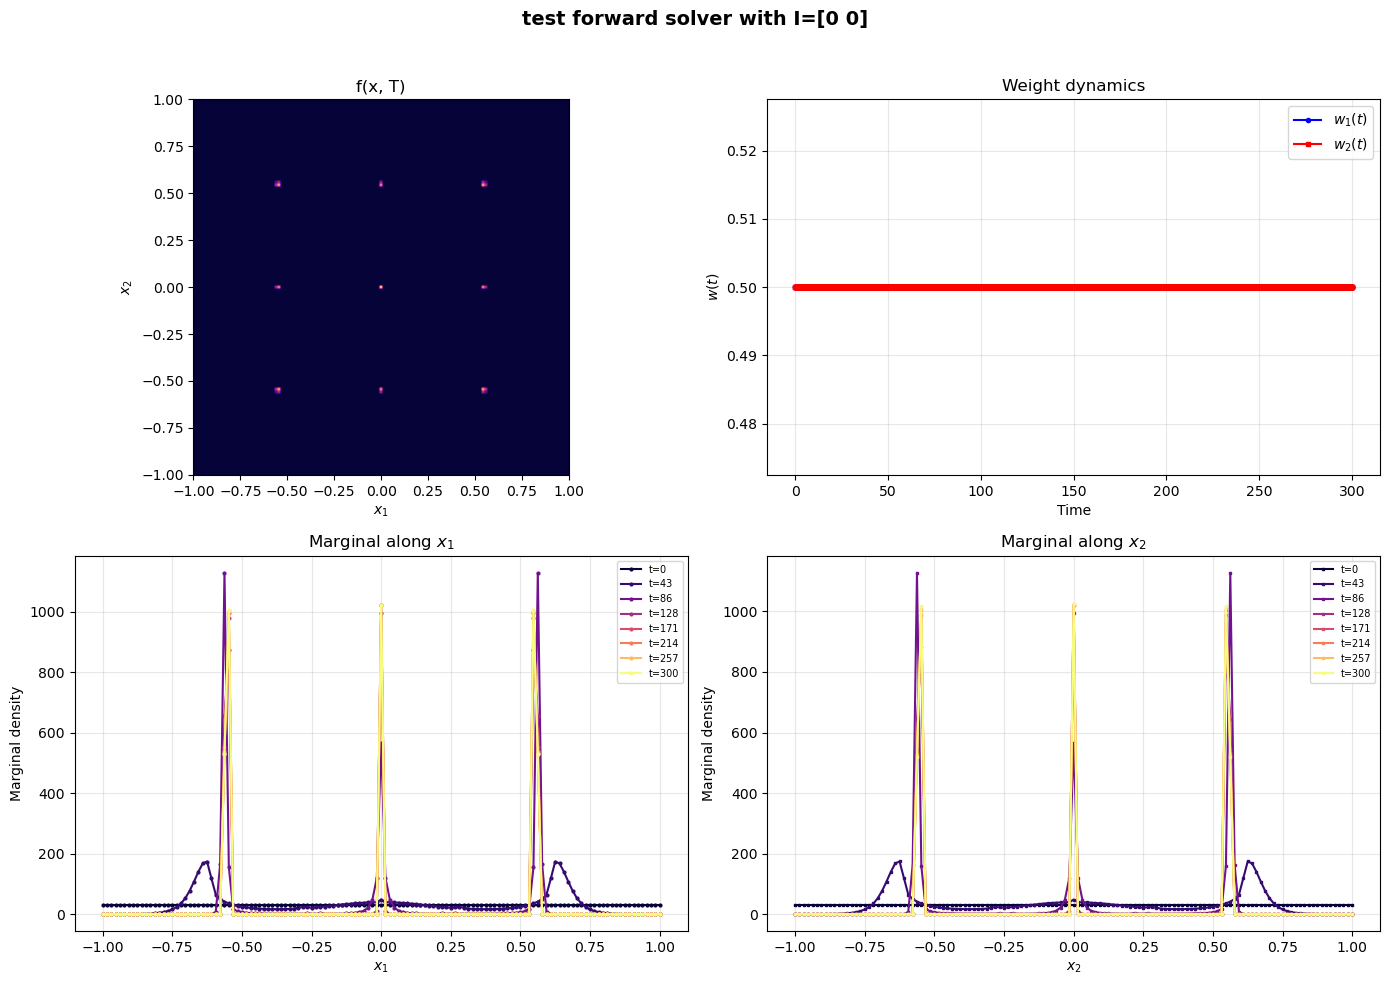

Forward solver test complete!


In [33]:
print("Testing forward solver...")
I_test = np.array([0,0])#np.array([0.75,0.25])#np.array([0.65, 0.35]) #np.array([0.5, 0.5])
r1 = 0.1
r2 = 0.4 # final time
T = 300
time_steps = int(np.floor(T / dt)) + 1  # number of time steps
#dt = 10
f_test, w_test, half_states = solve_pde_with_w(init_cond, w_init, I_test, dt, dx, time_steps, N, d, x_grid, beta, r1, r2, num_threads=None, backend="auto", direct_limit=1024, progress=False, return_cache=False)

print(f"\nForward solution complete!")
print(f"  Final mass: {np.sum(f_test[:, -1]) * (dx**2):.6f}")
print(f"  Final w: {w_test[:, -1]}")

# Visualizations
time_vals = np.arange(time_steps) * dt
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'test forward solver with I={I_test}', fontsize=14, fontweight='bold')

# Density at final time
axes[0,0].imshow(f_test[:, -1].reshape(N, N).T, extent=[-1, 1, -1, 1], origin='lower', cmap='plagma')
axes[0,0].set_title('f(x, T)')
axes[0,0].set_xlabel('$x_1$')
axes[0,0].set_ylabel('$x_2$')

# Opinion trajectory w(t)
axes[0,1].plot(time_vals, w_test[0, :], 'b-o', label='$w_1(t)$', markersize=3)
axes[0,1].plot(time_vals, w_test[1, :], 'r-s', label='$w_2(t)$', markersize=3)
axes[0,1].set_xlabel('Time')
axes[0,1].set_ylabel('$w(t)$')
axes[0,1].set_title('Weight dynamics')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Marginal densities at 8 time snapshots with ordered gradient colors
snapshots = np.linspace(0, time_steps - 1, 8, dtype=int)
colors = plt.get_cmap('plagma')(np.linspace(0, 1, len(snapshots)))

for t_idx, color in zip(snapshots, colors):
    marginal_x1 = np.sum(f_test[:, t_idx].reshape(N, N), axis=1)
    axes[1,0].plot(x_grid, marginal_x1, color=color, label=f't={time_vals[t_idx]:.0f}', marker='o', markersize=2)
axes[1,0].set_xlabel('$x_1$')
axes[1,0].set_ylabel('Marginal density')
axes[1,0].set_title('Marginal along $x_1$')
axes[1,0].legend(fontsize=7)
axes[1,0].grid(True, alpha=0.3)

# Marginal along x_2 at the same 8 snapshots (same color order)
for t_idx, color in zip(snapshots, colors):
    marginal_x2 = np.sum(f_test[:, t_idx].reshape(N, N), axis=0)
    axes[1,1].plot(x_grid, marginal_x2, color=color, label=f't={time_vals[t_idx]:.0f}', marker='s', markersize=2)
axes[1,1].set_xlabel('$x_2$')
axes[1,1].set_ylabel('Marginal density')
axes[1,1].set_title('Marginal along $x_2$')
axes[1,1].legend(fontsize=7)
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("Forward solver test complete!")

In [25]:
def variance_squared_cost_gradient(f, x_grid, dx, dt, T, variance_desired):
    """Euclidean gradient of dt/(4T)*(V-V_des)^2 for unit-mass f."""
    N = len(x_grid)
    X0, X1 = np.meshgrid(x_grid, x_grid, indexing="ij")
    ff = np.asarray(f).reshape(N, N)
    mass_weight = dx * dx
    mean0 = mass_weight * np.sum(X0 * ff)
    mean1 = mass_weight * np.sum(X1 * ff)
    radius2 = (X0 - mean0) ** 2 + (X1 - mean1) ** 2
    variance = mass_weight * np.sum(radius2 * ff)
    return (
        dt
        * mass_weight
        / ( T)
        * (variance - variance_desired)
        * radius2
    ).ravel()

In [27]:
def solve_adjoint(
    f_all,
    w_all,
    I_control,
    dt,
    dx,
    x_grid,
    beta,
    r1,
    r2,
    variance_desired,
    T=None,
    half_states=None,
    *,
    terminal_f=None,
    terminal_w=None,
    objective_gradient=None,
    forward_cache=None,
    num_threads=None,
    backend="auto",
    direct_limit=1024,
):
    """
    Scalable exact reverse mode of solve_pde_with_w.

    This is differentiable away from zero-velocity upwind switches and active
    clipping bounds. If supplied, objective_gradient is called as
    objective_gradient(f_at_kplus1, k+1) and must return an ordinary Euclidean
    derivative with respect to the flattened density.
    """
    if num_threads is not None:
        set_num_threads(int(num_threads))
    f_all = np.ascontiguousarray(f_all, dtype=np.float64)
    w_all = np.ascontiguousarray(w_all, dtype=np.float64)
    x_grid = np.asarray(x_grid, dtype=np.float64)
    N = len(x_grid)
    nt = f_all.shape[1]
    M = N * N
    if f_all.shape != (M, nt) or w_all.shape != (2, nt):
        raise ValueError("Expected f_all=(N**2, nt) and w_all=(2, nt).")
    if T is None:
        T = dt * max(nt - 1, 1)

    if half_states is None:
        half = np.empty((M, max(0, nt - 1)))
        for k in range(nt - 1):
            half[:, k], _ = _stage(
                f_all[:, k],
                w_all[0, k],
                0.5 * dt,
                dx,
                N,
                0,
                beta,
                r1,
                r2,
                backend,
                direct_limit,
            )
    else:
        half = np.ascontiguousarray(half_states, dtype=np.float64)

    bar_f = np.zeros_like(f_all)
    bar_w = np.zeros_like(w_all)
    if terminal_f is not None:
        bar_f[:, -1] = terminal_f
    if terminal_w is not None:
        bar_w[:, -1] = terminal_w

    dt_stage = 0.5 * dt
    for k in range(nt - 2, -1, -1):
        f0 = f_all[:, k]
        f_half = half[:, k]
        f1 = f_all[:, k + 1]
        w0 = w_all[0, k]

        if forward_cache is None:
            hx, dhx, rx0, rx1, ux = _stage_data(
                f0, w0, dx, N, 0, beta, r1, r2, backend, direct_limit
            )
            hy, dhy, ry0, ry1, uy = _stage_data(
                f_half, w0, dx, N, 1, beta, r1, r2, backend, direct_limit
            )
            x_data = (
                hx,
                dhx,
                rx0,
                rx1,
                ux,
                np.maximum(ux, 0.0),
                np.minimum(ux, 0.0),
            )
            y_data = (
                hy,
                dhy,
                ry0,
                ry1,
                uy,
                np.maximum(uy, 0.0),
                np.minimum(uy, 0.0),
            )
        else:
            x_data, y_data = forward_cache[k]

        forcing = variance_squared_cost_gradient(
            f1, x_grid, dx, dt, T, variance_desired
        )

        adj_half, grad_w_y, _ = _reverse_stage(
            bar_f[:, k + 1] + forcing,
            f1,
            f_half,
            y_data,
            dt_stage,
            dx,
            N,
            1,
            backend,
            direct_limit,
        )
        bar_f[:, k], grad_w_x, _ = _reverse_stage(
            adj_half,
            f_half,
            f0,
            x_data,
            dt_stage,
            dx,
            N,
            0,
            backend,
            direct_limit,
        )

        control = _control_at(I_control, k, 2)
        denominator = 1 + 0.5 * dt * np.sum(control)
        bar_w[:, k] = bar_w[:, k + 1] / denominator

        # The computational forward map calls tight_rectangle with w[0] and
        # sets the second kernel weight to 1-w[0]. Thus its direct PDE
        # derivative is represented by the first adjoint component.
        bar_w[0, k] += grad_w_x + grad_w_y

    return bar_f, bar_w

def warm_up(N, dx, beta, r1, r2, num_threads=None):
    """Compile Numba kernels before benchmarking a real simulation."""
    if num_threads is not None:
        set_num_threads(int(num_threads))
    f = np.ones(N * N)
    f /= np.sum(f) * dx * dx
    y, data = _stage(
        f, 0.5, 0.05, dx, N, 0, beta, r1, r2, "direct", 10**9
    )
    _reverse_stage(
        np.ones_like(f), y, f, data, 0.05, dx, N, 0, "direct", 10**9
    )
    _weight_update(np.array([0.5, 0.5]), np.array([0.5, 0.5]), 0.1, 2)

Testing backward solver...


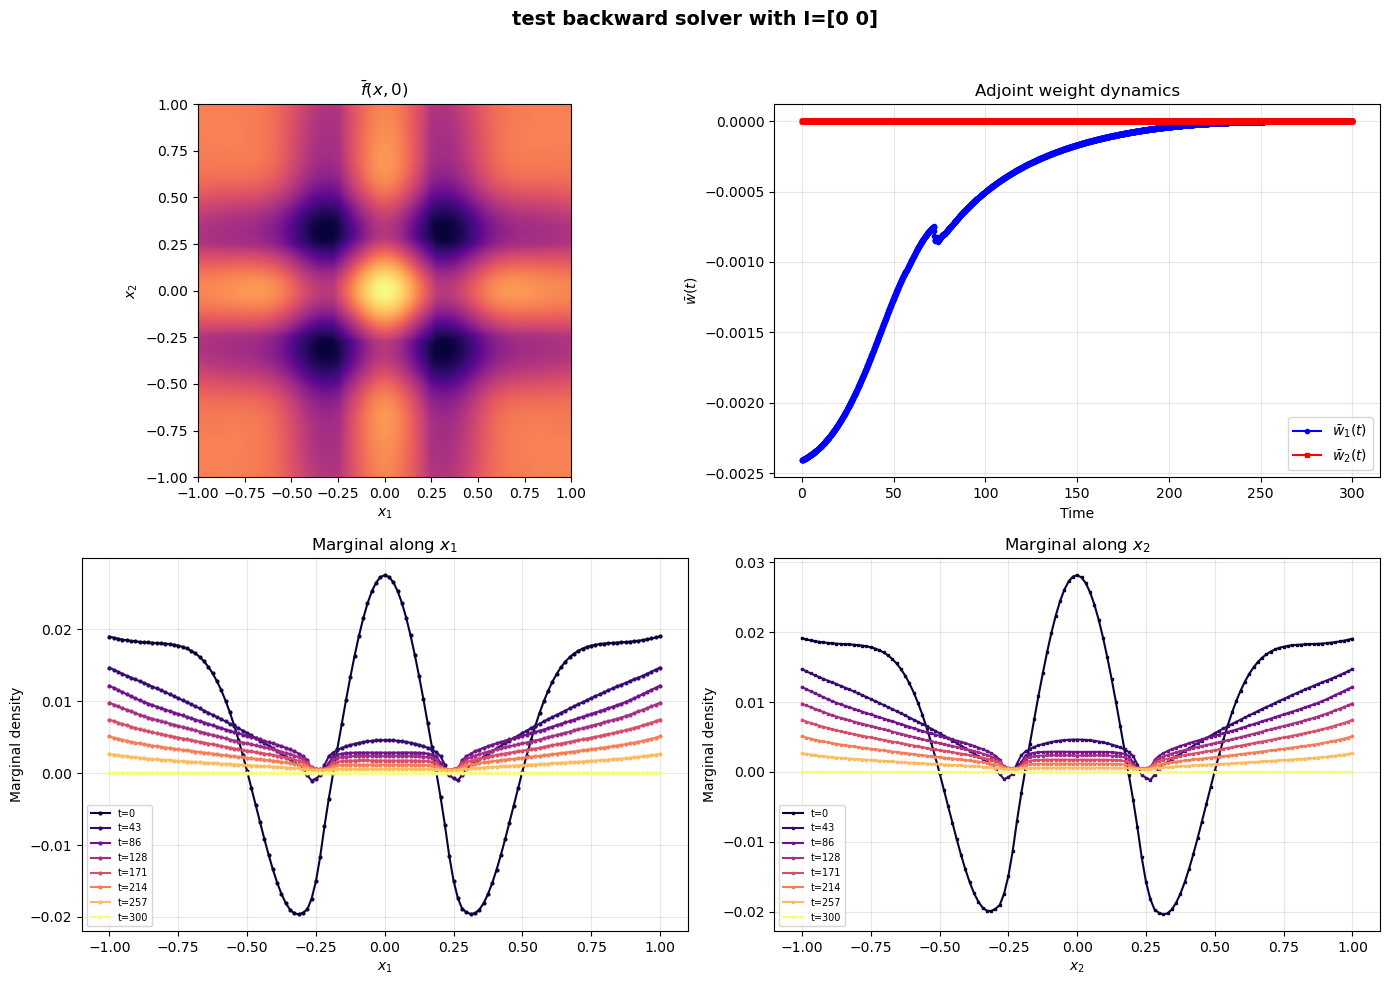

Backward solver test complete!


In [41]:
print("Testing backward solver...")

# Visualizations
time_vals = np.arange(time_steps) * dt
variance_desired = 0.0

fbar_all, wbar_all = solve_adjoint(f_test, w_test, I_test, dt, dx, x_grid, beta, r1, r2, variance_desired, T, half_states, terminal_f=None, terminal_w=None, objective_gradient=None, forward_cache=None, num_threads=None, backend="auto", direct_limit=1024)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'test backward solver with I={I_test}', fontsize=14, fontweight='bold')

# Density at final time
axes[0,0].imshow(fbar_all[:, 0].reshape(N, N).T, extent=[-1, 1, -1, 1], origin='lower', cmap='plagma')
axes[0,0].set_title(r'$\bar{f}(x, 0)$')
axes[0,0].set_xlabel('$x_1$')
axes[0,0].set_ylabel('$x_2$')

# Opinion trajectory w(t)
axes[0,1].plot(time_vals, wbar_all[0, :], 'b-o', label=r'$\bar{w}_1(t)$', markersize=3)
axes[0,1].plot(time_vals, wbar_all[1, :], 'r-s', label=r'$\bar{w}_2(t)$', markersize=3)
axes[0,1].set_xlabel('Time')
axes[0,1].set_ylabel(r'$\bar{w}(t)$')
axes[0,1].set_title('Adjoint weight dynamics')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Marginal densities at 8 time snapshots with ordered gradient colors
snapshots = np.linspace(0, time_steps - 1, 8, dtype=int)
colors = plt.get_cmap('plagma')(np.linspace(0, 1, len(snapshots)))

for t_idx, color in zip(snapshots, colors):
    marginal_x1 = np.sum(fbar_all[:, t_idx].reshape(N, N), axis=1)
    axes[1,0].plot(x_grid, marginal_x1, color=color, label=f't={time_vals[t_idx]:.0f}', marker='o', markersize=2)
axes[1,0].set_xlabel('$x_1$')
axes[1,0].set_ylabel('Marginal density')
axes[1,0].set_title('Marginal along $x_1$')
axes[1,0].legend(fontsize=7)
axes[1,0].grid(True, alpha=0.3)

# Marginal along x_2 at the same 8 snapshots (same color order)
for t_idx, color in zip(snapshots, colors):
    marginal_x2 = np.sum(fbar_all[:, t_idx].reshape(N, N), axis=0)
    axes[1,1].plot(x_grid, marginal_x2, color=color, label=f't={time_vals[t_idx]:.0f}', marker='s', markersize=2)
axes[1,1].set_xlabel('$x_2$')
axes[1,1].set_ylabel('Marginal density')
axes[1,1].set_title('Marginal along $x_2$')
axes[1,1].legend(fontsize=7)
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("Backward solver test complete!")

In [29]:
def instantaneous_objective(I_t, f_all, w_all, dt, dx, N, d, xgrid, T, nu, V_des):
    """One-step reduced objective from current state with control I_t."""
    X0, X1 = np.meshgrid(x_grid, x_grid, indexing="ij")
    mass_weight = dx * dx
    V_all = np.zeros(K+1)
    
    for k in range(K+1):
        ff = np.asarray(f_all[:,k]).reshape(N, N)
        mean0 = mass_weight * np.sum(X0 * ff)
        mean1 = mass_weight * np.sum(X1 * ff)
        radius2 = (X0 - mean0) ** 2 + (X1 - mean1) ** 2
        variance = mass_weight * np.sum(radius2 * ff)
        V_all[k] = variance.copy()
        
    J_track = (dt / (4*(T))) * np.sum((V_all - V_des)**2)
    J_ctrl = ( nu*K*dt / (2*d)) * np.sum(I_t**2)
    return J_track + J_ctrl

def instantaneous_gradient_adjoint(I_t, f_all, fhalf_all, w_all, dt, dx, N, d, xgrid, T, nu, V_des):
    """Theoretical reduced gradient for one time slice using adjoint variables."""
    
    fbar_all, wbar_all = solve_adjoint(f_all, w_all, I_t, dt, dx, x_grid, beta, r1, r2, V_des, T, fhalf_all, terminal_f=None, terminal_w=None, objective_gradient=None, forward_cache=None, num_threads=None, backend="auto", direct_limit=1024)

    grad_integrand = np.zeros(d)

    for t in range(K+1):
        wbar_t = wbar_all[:, t]
        scalar_w_wbar = float(np.dot(w_all[:,t], wbar_t))
        grad_integrand += dt*((1.0 / (d)) * (wbar_t - np.ones(d) * scalar_w_wbar) + (nu / d) * I_t) / ((K+1)*dt)

        
    return grad_integrand

In [43]:
# Loop through t taking random values of control to check gradient
V_des_opt =0.0
nu_opt = 0.0

r1 = 0.1
r2 = 0.4

K = 20

T = 90
time_steps = int(np.floor(T / dt)) + 1 

# Allocate trajectory/control storage

I_init = np.zeros((d, time_steps))
f_opt = np.zeros((N**d, time_steps))
grad1 = np.zeros((d, time_steps))
w_opt = np.zeros((d, time_steps))
J_all = np.zeros(time_steps)

f_opt[:, 0] = init_cond
w_opt[:, 0] = w_init

I_init[:, 0] = [np.random.uniform(0,1),np.random.uniform(0,1)]

from tqdm import tqdm

for t in tqdm(range(time_steps - 1)):
    f_cur = f_opt[:, t].copy()
    w_cur = w_opt[:, t].copy()
    
    c_k1 = I_init[:, t].copy()

   # calculate gradient according to adjoint description
    
    f_all, w_all, fhalf_all = solve_pde_with_w(f_cur, w_cur, c_k1, dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, backend="auto", direct_limit=1024, progress=False, return_cache=False)
    qk1 = instantaneous_gradient_adjoint(c_k1, f_all, fhalf_all, w_all, dt, dx, N, d, x_grid, K*dt, nu_opt, V_des_opt)
    J_opt = instantaneous_objective(c_k1, f_all, w_all, dt, dx, N, d, x_grid, K*dt, nu_opt, V_des_opt)

    f_next = f_all[:,1].copy()
    w_next = w_all[:,1].copy()

    # update arrays

    grad1[:,t] = np.copy(qk1)
    J_all[t] = np.copy(J_opt)
    f_opt[:,t+1] = np.copy(f_next)
    w_opt[:,t+1] = np.copy(w_next)
    
    if t + 1 < time_steps - 1:
        I_init[:,t+1] = [np.random.uniform(0,1),np.random.uniform(0,1)]
        

print(f"\n{'='*60}")
print("Gradient evaluations complete!")


100%|██████████| 900/900 [04:56<00:00,  3.03it/s]


Gradient evaluations complete!


In [45]:
# check the gradient we obtain against the finite difference gradient in direction h

eps = 10**(-3)
h = np.array([1,-1])
nu = 0.0
all_oursN128 = np.zeros(time_steps)
all_finite_diffN128 = np.zeros(time_steps)
for t in range(time_steps):
    our_grad = np.dot(grad1[:,t], h)
    all_oursN128[t] = our_grad.copy()
    f_all1, w_all1, fhalf_all1 = solve_pde_with_w(f_opt[:,t], w_opt[:,t], I_init[:,t] + eps*h, dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, progress=False)
    J1 = instantaneous_objective(I_init[:,t] + eps*h, f_all1, w_all1, dt, dx, N, d, x_grid, K*dt, nu, variance_desired)
    f_all2, w_all2, fhalf_all2 = solve_pde_with_w(f_opt[:,t], w_opt[:,t], I_init[:,t] - eps*h, dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, progress=False)
    J2 = instantaneous_objective(I_init[:,t] - eps*h, f_all2, w_all2, dt, dx, N, d, x_grid, K*dt, nu, variance_desired)
    finite_difference = (J1-J2)/(2*eps)
    all_finite_diffN128[t] = finite_difference.copy()
    print(f'our gradient', our_grad, f'finite difference', finite_difference, f'error<epsilon?', np.abs(our_grad - finite_difference)<eps)

our gradient 0.00014608497800572593 finite difference 0.0001365825746182936 error<epsilon? True
our gradient -0.00015732114495830969 finite difference -0.00014517771947802904 error<epsilon? True
our gradient 0.00010357208220552 finite difference 9.518475049818953e-05 error<epsilon? True
our gradient 7.977422610290963e-05 finite difference 7.228850566060041e-05 error<epsilon? True
our gradient 4.729653367152714e-05 finite difference 4.158562436767932e-05 error<epsilon? True
our gradient -2.160975744638081e-05 finite difference -2.052644561267858e-05 error<epsilon? True
our gradient 3.112942039194064e-05 finite difference 2.8013563163620248e-05 error<epsilon? True
our gradient -3.989728921586136e-05 finite difference -3.720558729158885e-05 error<epsilon? True
our gradient 2.924747321054952e-05 finite difference 2.6205577118021406e-05 error<epsilon? True
our gradient 3.788571691416375e-05 finite difference 3.382167890891852e-05 error<epsilon? True
our gradient 3.819163902579792e-05 finite

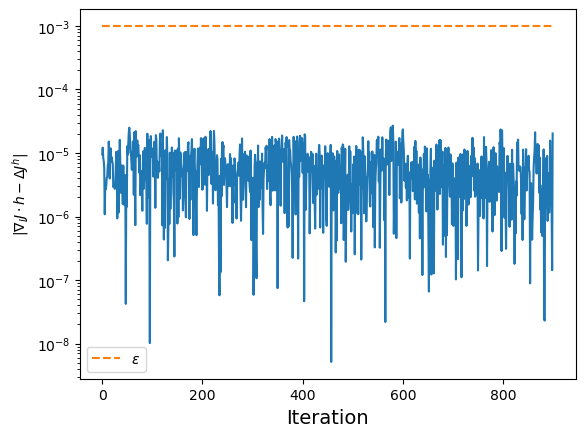

In [57]:
plt.semilogy(abs(all_finite_diffN128-all_oursN128)[:-1])
plt.plot(eps*np.ones(time_steps), '--', label=r'$\varepsilon$')
plt.ylabel(r'$|\nabla_IJ\cdot h - \Delta J^h|$')
plt.xlabel('Iteration', fontsize=14)
plt.legend()
plt.show()

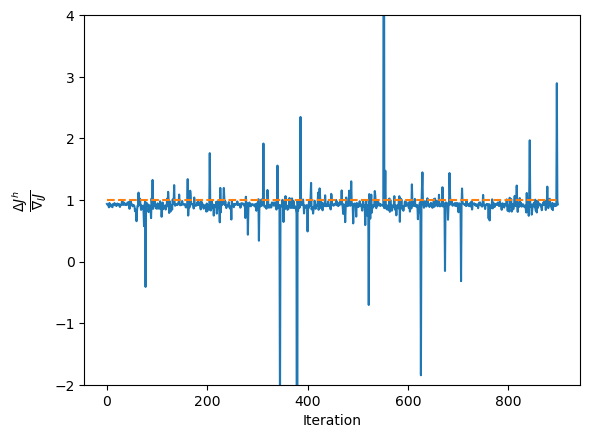

In [63]:
plt.plot(all_finite_diffN128[:-1]/all_oursN128[:-1])
plt.plot(np.ones(time_steps-1),'--', label='1')
plt.ylim(-2,4)
plt.xlabel('Iteration')
plt.ylabel(r'$\frac{\Delta J^h}{\nabla_IJ}$', fontsize=14)
plt.show()

Computing Jhat maps for 45 frames (every 20 timestep) on a 9x9 control grid...
  computed 4/45 frames
  computed 8/45 frames
  computed 12/45 frames
  computed 16/45 frames
  computed 20/45 frames
  computed 24/45 frames
  computed 28/45 frames
  computed 32/45 frames
  computed 36/45 frames
  computed 40/45 frames
  computed 44/45 frames


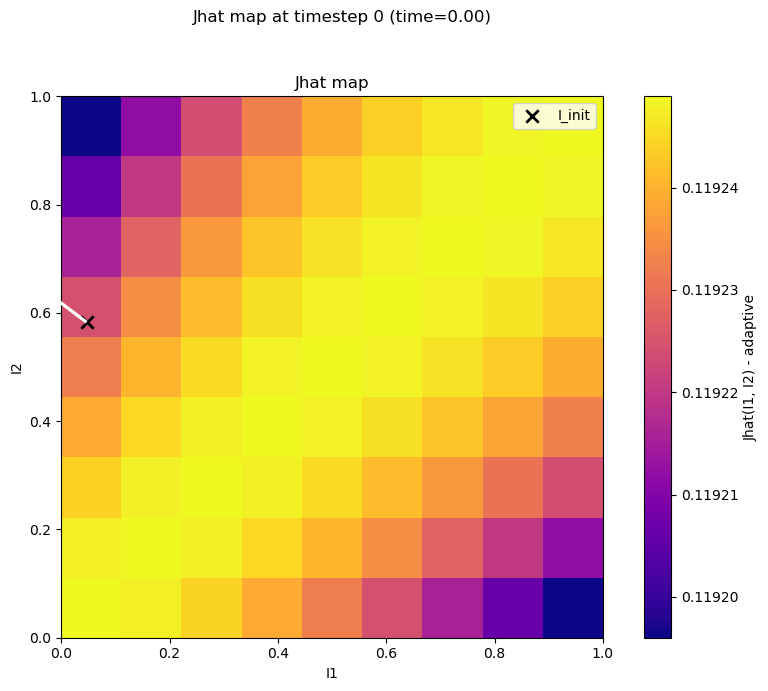

Falling back to inline HTML animation with play/pause controls...


In [95]:
# visualise gradient on the discrete cost landscape

# normalise and find steepest descent direction for plotting
for t in range(time_steps):
    grad1[:,t] = - grad1[:,t]/np.linalg.norm(grad1[:,t])

import os
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Video, display

# Animation speed/quality controls
JHAT_ANIM_GRID_N = 9
JHAT_ANIM_FRAME_STRIDE = 20

# Required trajectory data from optimization loop
required_vars = ['f_opt', 'w_opt', 'I_init', 'grad1',
                 'time_steps', 'dt', 'dx', 'N', 'd', 'x_grid', 'T']
missing = [name for name in required_vars if name not in globals()]
if missing:
    raise RuntimeError(
        "Missing required variables for Jhat animation: " + ", ".join(missing)
    )

# Cost parameters
V_des_anim = float(globals().get('V_des_opt', 0.0))
nu_anim = float(globals().get('nu_opt', 0.0))
frame_stride = max(1, int(JHAT_ANIM_FRAME_STRIDE))
control_grid_n = max(5, min(int(JHAT_ANIM_GRID_N), 33))


# Control ranges
if 'I1range' in globals() and len(I1range) > 1:
    i1_min, i1_max = float(np.min(I1range)), float(np.max(I1range))
else:
    i1_min, i1_max = 0.0, 1.0

if 'I2range' in globals() and len(I2range) > 1:
    i2_min, i2_max = float(np.min(I2range)), float(np.max(I2range))
else:
    i2_min, i2_max = 0.0, 1.0

I1_grid = np.linspace(i1_min, i1_max, control_grid_n)
I2_grid = np.linspace(i2_min, i2_max, control_grid_n)

n1 = len(I1_grid)
n2 = len(I2_grid)
frame_indices = np.arange(0, time_steps - 1, frame_stride, dtype=int)
frame_count = len(frame_indices)

print(f"Computing Jhat maps for {frame_count} frames (every {frame_stride} timestep) "
      f"on a {n1}x{n2} control grid...")

Jhat_time = np.zeros((frame_count, n1, n2), dtype=float)


for f_idx, t in enumerate(frame_indices):
    f_cur_t = f_opt[:, t]
    w_cur_t = w_opt[:, t]
    our_grad = grad1[:,t]
    J_cur = J_all[t]

    for i1, I1_val in enumerate(I1_grid):
        for i2, I2_val in enumerate(I2_grid):
            f_all, w_all, fhalf_all = solve_pde_with_w(f_cur_t, w_cur_t, np.array([I1_val, I2_val]), dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, backend="auto", direct_limit=1024, progress=False, return_cache=False)
            Jhat_time[f_idx, i1, i2] = instantaneous_objective(np.array([I1_val, I2_val]), f_all, w_all, dt, dx, N, d, x_grid, K*dt, nu_opt, V_des_opt)

    if (f_idx + 1) % max(1, frame_count // 10) == 0:
        print(f"  computed {f_idx + 1}/{frame_count} frames")

# Adaptive initial limits
a_min = float(np.min(Jhat_time[0]))
a_max = float(np.max(Jhat_time[0]))
if a_max <= a_min:
    a_max = a_min + 1e-12

# Figure layout: adaptive-scale map only
fig_jhat = plt.figure(figsize=(9, 7))
ax_adapt = fig_jhat.add_subplot(111)

im_adapt = ax_adapt.imshow(
    Jhat_time[0],
    origin='lower',
    extent=[I1_grid[0], I1_grid[-1], I2_grid[0], I2_grid[-1]],
    aspect='auto',
    vmin=a_min,
    vmax=a_max,
    cmap='plasma'
)
cb_adapt = fig_jhat.colorbar(im_adapt, ax=ax_adapt)
cb_adapt.set_label('Jhat(I1, I2) - adaptive')


init_adapt = ax_adapt.scatter(
    [I_init[0, frame_indices[0]]],
    [I_init[1, frame_indices[0]]],
    c='black', edgecolors='black', s=80, marker='x', linewidths=2, zorder=3, label='I_init'
)

start0 = I_init[:, frame_indices[0]]

grad0 = grad1[:, frame_indices[0]]

arrow_adapt = ax_adapt.quiver(
    start0[0], start0[1], grad0[0], grad0[1],
    angles='xy', scale_units='xy', scale=1,
    color='white', width=0.006, zorder=4)

ax_adapt.set_xlim(I1_grid[0], I1_grid[-1])
ax_adapt.set_ylim(I2_grid[0], I2_grid[-1])
ax_adapt.set_xlabel('I1')
ax_adapt.set_ylabel('I2')
ax_adapt.set_title('Jhat map')
ax_adapt.legend(loc='upper right')
ax_adapt.set_box_aspect(1)

title = fig_jhat.suptitle(
    f'Jhat map at timestep {frame_indices[0]} (time={frame_indices[0] * dt:.2f})'
)

# ------------------------------------------------------------
# UPDATE FUNCTION
# ------------------------------------------------------------
def _update(frame_idx):
    t = frame_indices[frame_idx]
    frame = Jhat_time[frame_idx].T

    # Update heatmap
    im_adapt.set_data(frame)

    # Adaptive color scaling
    cur_min = float(np.min(frame))
    cur_max = float(np.max(frame))
    if cur_max <= cur_min:
        cur_max = cur_min + 1e-12
    im_adapt.set_clim(cur_min, cur_max)
    cb_adapt.update_normal(im_adapt)

    # Update markers
    i_init_now = np.array([I_init[0, t], I_init[1, t]])
    grad_now = grad1[:, t].copy()

    init_adapt.set_offsets(i_init_now.reshape(1, 2))

    # Update vector arrow
    arrow_adapt.set_offsets(i_init_now.reshape(1, 2))
    arrow_adapt.set_UVC(grad_now[0], grad_now[1])

    title.set_text(f'Jhat map at timestep {t} (time={t * dt:.2f})')

    return [im_adapt, init_adapt, arrow_adapt, title]

# ------------------------------------------------------------
# RUN ANIMATION
# ------------------------------------------------------------
anim_jhat = FuncAnimation(
    fig_jhat, _update, frames=frame_count, interval=300, blit=False
)

mp4_name = 'jhat_over_time_with_controls.mp4'
mp4_saved = False


plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

if mp4_saved and os.path.exists(mp4_name):
    print('Displaying MP4 movie with playback controls...')
    display(Video(mp4_name, embed=True, html_attributes='controls'))
else:
    print('Falling back to inline HTML animation with play/pause controls...')
    display(HTML(anim_jhat.to_jshtml()))